# Tennis forehand from one racket sensor: a walkthrough

A small sensor sits in the end of a tennis racket handle. It measures **acceleration** (how hard the racket is pushed),
**rotation speed** (how fast it spins) and **orientation** (which way it points). There is no camera and no sensor on the body.

We ask two questions:

1. Can the sensor tell **which part of the forehand** the player is in? (5 phases)
2. Can it tell **how far the chest turned**? (trunk rotation, a key coaching number)

**Important:** the data is **simulated** (seed 7), not recorded from real players. We know the right answers exactly, which lets us grade the methods.
Every score here is an *upper bound*: real players and real sensors will score lower.

This notebook reads the files in `data/` (made by `export_dataset.py`). It does not re-simulate anything.

In [1]:
import sys, json, time
from pathlib import Path
sys.path.insert(0, str(Path('..') / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.spatial.transform import Rotation as Rot

import experiment as E                      # reuse: rotation_rows, event_scores, rot_metrics, summarise
from features import session_features
from hmm import PhaseHMM
from metrics import frame_scores
from simulate import FS, G, PHASES

T_START = time.time()
DATA = Path('..') / 'data'
players = pd.read_csv(DATA / 'players.csv')
raw = pd.read_csv(DATA / 'raw_imu.csv.gz', dtype={c: np.float32 for c in
      ['acc_x','acc_y','acc_z','gyr_x','gyr_y','gyr_z','quat_x','quat_y','quat_z','quat_w']})
labels = pd.read_csv(DATA / 'labels.csv.gz')
frames = pd.read_csv(DATA / 'frame_features.csv.gz')
FEAT = list(frames.columns[7:])
frames[FEAT] = frames[FEAT].astype(np.float32)
S = json.load(open('../results/summary.json'))   # only used to compare numbers at the end
print(f'raw_imu: {len(raw):,} rows | labels: {len(labels):,} rows | frame_features: {len(frames):,} rows x {len(FEAT)} features')
print(f'{players.shape[0]} players, sessions per player: {raw.session.nunique()}')
PH_COL = ['#d9d9d9', '#6baed6', '#fd8d3c', '#74c476', '#9e9ac8']

raw_imu: 540,685 rows | labels: 564,924 rows | frame_features: 282,467 rows x 60 features
12 players, sessions per player: 2


## 1. What the data is

Three kinds of rows:

* **`raw_imu`**: what the racket sensor actually sends over Bluetooth, about 200 times a second. Some packets get lost,
  so some moments are missing (`lost_before` counts how many readings were lost just before each row).
* **`labels`**: the true answers on a perfect 200 Hz clock: the phase, the chest angle, the racket's heading and more.
* **`frame_features`**: 60 summary numbers computed every 10 ms. This is what the classifiers see.

Below is one forehand. Coloured bands are the true phases:
grey = idle, blue = backswing, orange = forward swing, green = follow-through, purple = recovery.

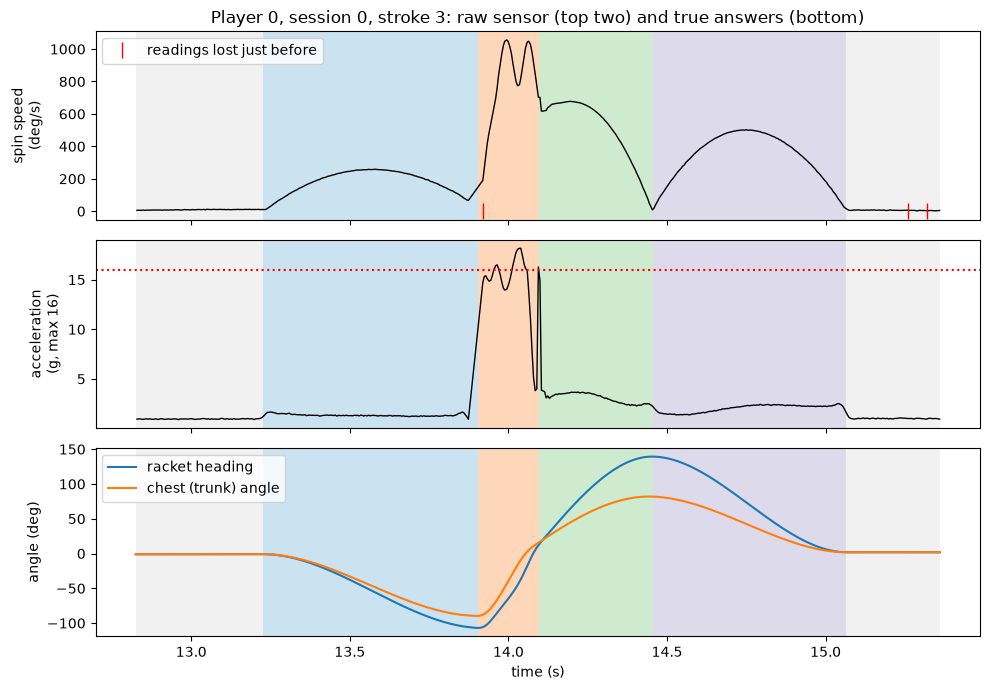

share of 200 Hz readings that arrived: 95.7%


In [2]:
def phase_bands(ax, t, ph):
    cut = np.flatnonzero(np.diff(ph)) + 1
    for a, b in zip(np.r_[0, cut], np.r_[cut, len(ph)]):
        ax.axvspan(t[a], t[min(b, len(t) - 1)], color=PH_COL[ph[a]], alpha=0.35, lw=0)

P0, S0, STROKE = 0, 0, 3
lab0 = labels[(labels.player == P0) & (labels.session == S0)]
st = lab0[lab0.stroke_id == STROKE]
t_lo, t_hi = st.t.iloc[0] - 0.4, st.t.iloc[-1] + 0.3
L = lab0[(lab0.t >= t_lo) & (lab0.t <= t_hi)]
R = raw[(raw.player == P0) & (raw.session == S0) & (raw.t >= t_lo) & (raw.t <= t_hi)]

fig, ax = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
ax[0].plot(R.t, np.sqrt(R.gyr_x**2 + R.gyr_y**2 + R.gyr_z**2), 'k', lw=1)
ax[0].set_ylabel('spin speed\n(deg/s)')
lost = R[R.lost_before > 0]
ax[0].plot(lost.t, np.zeros(len(lost)), 'r|', ms=12, label='readings lost just before')
ax[0].legend(loc='upper left')
ax[1].plot(R.t, np.sqrt(R.acc_x**2 + R.acc_y**2 + R.acc_z**2), 'k', lw=1)
ax[1].axhline(16, ls=':', c='r'); ax[1].set_ylabel('acceleration\n(g, max 16)')
ax[2].plot(L.t, L.racket_heading_deg, label='racket heading')
ax[2].plot(L.t, L.trunk_angle_deg, label='chest (trunk) angle')
ax[2].set_ylabel('angle (deg)'); ax[2].set_xlabel('time (s)'); ax[2].legend(loc='upper left')
for a in ax:
    phase_bands(a, L.t.values, L.phase.values)
ax[0].set_title(f'Player {P0}, session {S0}, stroke {STROKE}: raw sensor (top two) and true answers (bottom)')
plt.tight_layout(); plt.show()
print('share of 200 Hz readings that arrived: %.1f%%' % (100 * len(raw) / len(labels)))

What to notice: the racket spins up to well over 1000 deg/s in the forward swing, the accelerometer **maxes out at 16 g**,
and the ball impact is a sharp spike at the start of the follow-through. The chest turns away first (negative angle), then
unwinds just before the racket does.

## 2. Features: the 60 numbers per 10 ms

A single raw reading says little. So every 10 ms we compute 60 numbers that describe the motion around that moment.
None of them depends on which way the player faces the court (the sensor cannot know that; it has no compass).

| group | count | plain meaning |
|---|---|---|
| instant values | 13 | spin speed, spin around the vertical (`yaw_rate`), total and gravity-free acceleration, tip up/down angle (`elev`), face tilt, spin and push along each handle axis |
| short / medium / long windows | 36 | average and wobble (std) of 6 signals over 25 ms, 105 ms and 305 ms |
| past vs future | 8 | average of 4 signals over the 150 ms before vs after: is the swing speeding up or slowing down? |
| turn so far / turn to come | 2 | how much the racket turned about the vertical in the last / next 300 ms |
| saturation | 1 | how often the sensor hit its 16 g / 2000 deg/s limit nearby |

gyr_mag, yaw_rate, acc_mag, lin_mag, lin_vert, elev, face_tilt, gyr_x, gyr_y, gyr_z, acc_x, acc_y, acc_z, gyr_mag_m5, gyr_mag_s5, yaw_rate_m5, yaw_rate_s5, acc_mag_m5, acc_mag_s5, elev_m5, elev_s5, face_tilt_m5, face_tilt_s5, jerk_m5, jerk_s5, gyr_mag_m21, gyr_mag_s21, yaw_rate_m21, yaw_rate_s21, acc_mag_m21, acc_mag_s21, elev_m21, elev_s21, face_tilt_m21, face_tilt_s21, jerk_m21, jerk_s21, gyr_mag_m61, gyr_mag_s61, yaw_rate_m61, yaw_rate_s61, acc_mag_m61, acc_mag_s61, elev_m61, elev_s61, face_tilt_m61, face_tilt_s61, jerk_m61, jerk_s61, yaw_rate_past, yaw_rate_fut, elev_past, elev_fut, gyr_mag_past, gyr_mag_fut, face_tilt_past, face_tilt_fut, dyaw_past, dyaw_fut, sat_frac


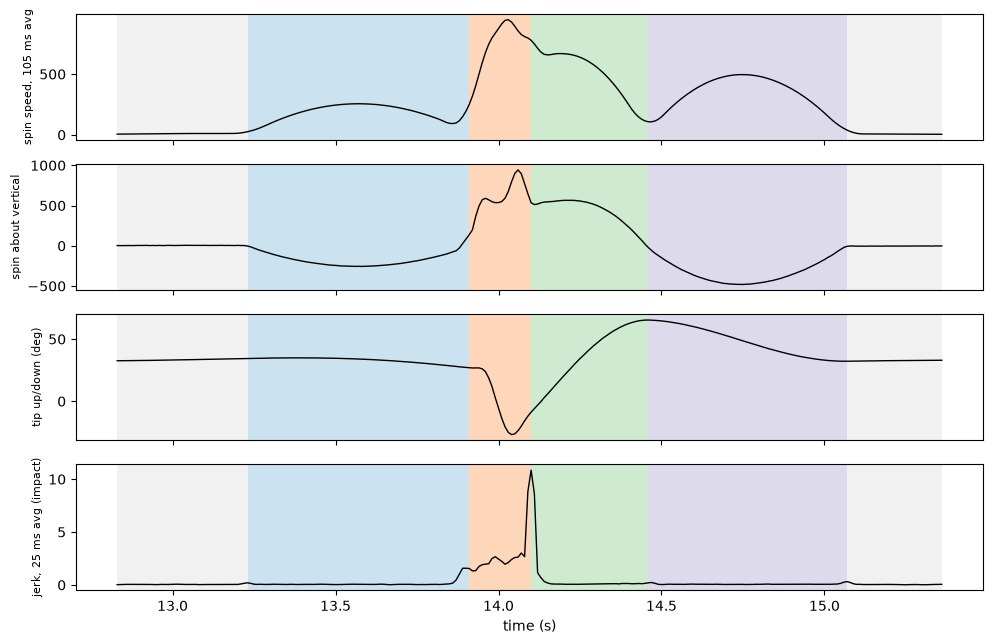

,t,phase,missing,gyr_mag_m21,yaw_rate,elev,jerk_m5
1283,12.83,0,0,5.390000,3.040000,32.560001,0.02
1308,13.08,0,0,10.630000,3.720000,33.570000,0.03
1333,13.33,1,0,127.879997,-129.649994,34.830002,0.04
1358,13.58,1,0,255.440002,-256.799988,33.869999,0.05
1383,13.83,1,0,113.879997,-113.480003,29.080000,0.06
1408,14.08,2,0,809.070007,771.340027,-15.750000,2.67
1433,14.33,3,0,487.359985,443.769989,52.570000,0.10
1458,14.58,4,0,335.880005,-331.470001,61.130001,0.07
1483,14.83,4,0,460.709991,-439.450012,42.180000,0.08
1508,15.08,0,0,26.330000,-2.090000,32.230000,0.22


In [3]:
print(', '.join(FEAT))
F = frames[(frames.player == P0) & (frames.session == S0) & (frames.t >= t_lo) & (frames.t <= t_hi)]
show = [('gyr_mag_m21', 'spin speed, 105 ms avg'), ('yaw_rate', 'spin about vertical'),
        ('elev', 'tip up/down (deg)'), ('jerk_m5', 'jerk, 25 ms avg (impact)')]
fig, ax = plt.subplots(len(show), 1, figsize=(10, 6.5), sharex=True)
for a, (c, name) in zip(ax, show):
    a.plot(F.t, F[c], 'k', lw=1); a.set_ylabel(name, fontsize=8)
    phase_bands(a, F.t.values, F.phase.values)
ax[-1].set_xlabel('time (s)'); plt.tight_layout(); plt.show()
display(F[['t', 'phase', 'missing'] + [c for c, _ in show]].iloc[::25].round(2))

**Check:** the feature file should be exactly what `src/features.py` produces from the raw file. We rebuild the features
from `raw_imu` for every session (we also need the per-sample signals later for chest rotation) and compare.

In [4]:
KEEP_CH = E.KEEP_CH
lab_groups = {k: g for k, g in labels.groupby(['player', 'session'], sort=False)}
raw_groups = {k: g for k, g in raw.groupby(['player', 'session'], sort=False)}
frm_groups = {k: g for k, g in frames.groupby(['player', 'session'], sort=False)}

def true_strokes(ph, sid):
    out = []
    for k in range(sid.max() + 1):
        idx = np.flatnonzero(sid == k)
        p = ph[idx]
        first = lambda c: int(idx[np.argmax(p >= c)])
        out.append(dict(onset=int(idx[0]), reversal=first(2), contact=first(3), ft_end=first(4), end=int(idx[-1]) + 1))
    return out

sessions, worst = [], 0.0
for key, lg in lab_groups.items():
    rg, fg = raw_groups[key], frm_groups[key]
    stream = dict(t=rg.t.values, acc=rg[['acc_x','acc_y','acc_z']].values.astype(float) * G,
                  gyr=np.deg2rad(rg[['gyr_x','gyr_y','gyr_z']].values.astype(float)),
                  quat=rg[['quat_x','quat_y','quat_z','quat_w']].values.astype(float))
    f = session_features(stream, len(lg))
    X = fg[FEAT].values
    worst = max(worst, float(np.median(np.abs(f['X'] - X))))
    ph, sid = lg.phase.values, lg.stroke_id.values
    clean = dict(t=lg.t.values, label=ph, ang_trunk=lg.trunk_angle_deg.values, alpha=lg.racket_heading_deg.values,
                 acc=lg[['clean_acc_x','clean_acc_y','clean_acc_z']].values * G,
                 gyr=np.deg2rad(lg[['clean_gyr_x','clean_gyr_y','clean_gyr_z']].values),
                 R_s=Rot.from_quat(lg[['clean_quat_x','clean_quat_y','clean_quat_z','clean_quat_w']].values),
                 strokes=true_strokes(ph, sid))
    sessions.append(dict(pid=key[0], sess=key[1], X=X, names=FEAT, centres=fg['sample'].values,
                         missing=fg.missing.values.astype(bool), y=fg.phase.values.astype(int),
                         ch={k: f['ch'][k].astype(np.float32) for k in KEEP_CH}, clean=clean))
    del f, stream
print(f'{len(sessions)} sessions rebuilt; worst per-session median |file - recomputed| feature difference: {worst:.2e}')

24 sessions rebuilt; worst per-session median |file - recomputed| feature difference: 2.38e-05


## 3. First models: frame-by-frame classifiers

A **classifier** looks at the 60 numbers of one 10 ms frame and guesses the phase. We try two:

* **Logistic regression (LR):** a weighted sum of the features, one score per phase. Simple and fast.
* **Gradient boosting (HGB):** many small decision trees added together. It can learn bends and thresholds that LR cannot.

Neither knows that phases come in a fixed order. They judge each frame alone.

To test fairly we **hide one player completely**, train on the other 11, and test on the hidden one (more in section 6).
Here we show it for player 0 only.

In [5]:
def fit_fold(pid):
    tr = [d for d in sessions if d['pid'] != pid]
    Xtr = np.vstack([d['X'][::2] for d in tr]); ytr = np.concatenate([d['y'][::2] for d in tr])
    lr = E.make_pipeline(E.StandardScaler(), E.LogisticRegression(max_iter=400, C=1.0)).fit(Xtr, ytr)
    hgb = E.HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1, max_leaf_nodes=31,
                                           random_state=0).fit(Xtr, ytr)
    hmm = PhaseHMM().fit([d['y'] for d in tr])
    return lr, hgb, hmm

t0 = time.time()
FOLD0 = fit_fold(0)
lr0, hgb0, hmm0 = FOLD0
d0 = [d for d in sessions if d['pid'] == 0 and d['sess'] == 0][0]
P_lr0, P_hgb0 = lr0.predict_proba(d0['X']), hgb0.predict_proba(d0['X'])
for name, P in [('LR', P_lr0), ('HGB', P_hgb0)]:
    s = frame_scores(d0['y'], P.argmax(1))
    print(f"{name:4s} frame F1 {s['macro_f1']:.1f}%   edit score {s['edit']:.1f}%   "
          f"per phase: {np.round(s['per_class'], 1)}")
print(f'(trained in {time.time() - t0:.0f}s)')

LR   frame F1 98.7%   edit score 95.0%   per phase: [99.4 98.5 98.3 98.7 98.7]
HGB  frame F1 98.4%   edit score 100.0%   per phase: [99.7 99.1 96.4 98.  99. ]
(trained in 33s)


Both are about 98% right per frame. But the **edit score** (does the sequence of phases look like real forehands?)
is lower: a few frames flip to an impossible phase for a moment. That is **flicker**.

## 4. The HMM: adding common sense

A forehand always goes **idle → backswing → forward swing → follow-through → recovery → idle**, and no phase can last only 20 ms.

A **hidden Markov model (HMM)** encodes exactly those two rules:

* the **order** of phases is fixed (it cannot jump from backswing to recovery);
* each phase has a **minimum length**, learned from training players (0.6 × their shortest typical duration).

It takes the classifier's per-frame guesses and finds the single most likely sequence that obeys the rules
(the Viterbi algorithm). It learns only about 15 numbers (durations and how common each phase is), so it needs very little data.

LR       frame F1 98.7%   edit 95.0%
LR+HMM   frame F1 98.9%   edit 100.0%


HGB      frame F1 98.4%   edit 100.0%
HGB+HMM  frame F1 98.3%   edit 100.0%
HMM states per phase (minimum frames): [77, 25, 8, 14, 25]


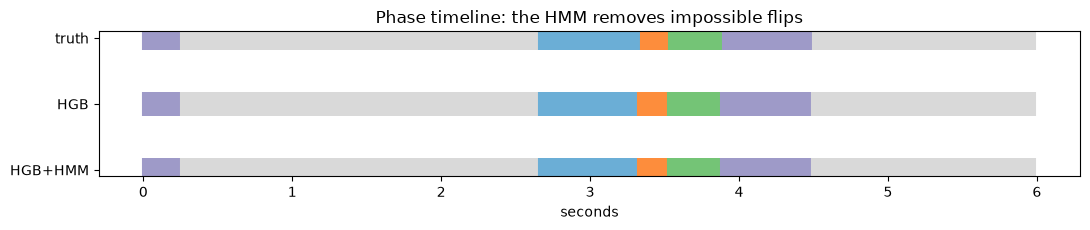

In [6]:
y_lr_hmm = hmm0.decode(P_lr0, d0['missing']); y_hgb_hmm = hmm0.decode(P_hgb0, d0['missing'])
for name, yp in [('LR', P_lr0.argmax(1)), ('LR+HMM', y_lr_hmm), ('HGB', P_hgb0.argmax(1)), ('HGB+HMM', y_hgb_hmm)]:
    s = frame_scores(d0['y'], yp); print(f"{name:8s} frame F1 {s['macro_f1']:.1f}%   edit {s['edit']:.1f}%")
print('HMM states per phase (minimum frames):', hmm0.n_states)

# where does flicker happen? show the stretch with the most HGB mistakes
yh = P_hgb0.argmax(1); bad = np.convolve((yh != d0['y']).astype(int), np.ones(300), 'same')
c = int(np.argmax(bad)); sl = slice(max(c - 300, 0), c + 300)
fig, ax = plt.subplots(figsize=(11, 2.4))
for row, (name, yy) in enumerate([('truth', d0['y']), ('HGB', yh), ('HGB+HMM', y_hgb_hmm)]):
    seg = yy[sl]
    ax.scatter(np.arange(len(seg)) / 100, np.full(len(seg), -row), c=[PH_COL[k] for k in seg], marker='|', s=300)
ax.set_yticks([0, -1, -2]); ax.set_yticklabels(['truth', 'HGB', 'HGB+HMM']); ax.set_xlabel('seconds')
ax.set_title('Phase timeline: the HMM removes impossible flips'); plt.tight_layout(); plt.show()

## 5. Missing data (brief)

Bluetooth loses readings, often several in a row. We handle it in three steps:

1. Put every reading back on a regular 200 Hz grid using its **timestamp** (not its position in the list).
2. Fill **short gaps** (up to 50 ms) by drawing a straight line between the neighbours.
3. Mark **longer gaps** as *missing*. For those frames the HMM ignores the classifier and lets the phase rules fill the hole.

Filling gaps with zeros instead would look like the racket suddenly freezing, which confuses every model.

In [7]:
n_lost = int(raw.lost_before.sum())
print(f'readings lost: {n_lost:,} of {len(labels):,} ({100 * n_lost / len(labels):.1f}%)')
print(f'frames marked missing (gap > 50 ms): {int(frames.missing.sum()):,} of {len(frames):,} '
      f'({100 * frames.missing.mean():.2f}%)')
d_m = max((d for d in sessions if d['pid'] == 0), key=lambda d: d['missing'].sum())
P = hgb0.predict_proba(d_m['X'])
a = frame_scores(d_m['y'], hmm0.decode(P, d_m['missing']))['macro_f1']
b = frame_scores(d_m['y'], hmm0.decode(P, None))['macro_f1']
print(f'player 0 session {d_m["sess"]}: HGB+HMM F1 with missing-flag {a:.2f}% vs ignoring it {b:.2f}%')

readings lost: 24,237 of 564,924 (4.3%)
frames marked missing (gap > 50 ms): 6,470 of 282,467 (2.29%)


player 0 session 1: HGB+HMM F1 with missing-flag 98.79% vs ignoring it 99.05%


## 6. Fair testing: leave one player out

If the same player appears in training and testing, a model can memorise that player's style and look better than it is.
So we run **12 rounds**: each round hides one player, trains on the other 11, and tests on both sessions of the hidden player.

In the same loop we also train the chest-rotation models (section 7), so everything is computed once.
Scores reported:

* **frame F1**: how many 10 ms frames get the right phase (balanced across phases), in %;
* **edit score**: whether the order of phases is right (100 = no flicker);
* **contact error**: how far the detected ball impact is from the true one, in milliseconds.

In [8]:
def run_fold(pid, models=None):
    lr, hgb, hmm = models or fit_fold(pid)
    tr = [d for d in sessions if d['pid'] != pid]; te = [d for d in sessions if d['pid'] == pid]
    fold = dict(pid=pid, sessions=[], robustness={})
    rx, ry, rxo, ryo = [], [], [], []
    for d in tr:
        a, b_, _ = E.rotation_rows(d, d['y']); rx.append(a); ry.append(b_)
        a, b_, _ = E.rotation_rows(d, d['y'], oracle=True); rxo.append(a); ryo.append(b_)
    rx, ry, rxo, ryo = np.vstack(rx), np.concatenate(ry), np.vstack(rxo), np.concatenate(ryo)
    k_share = float(np.sum(rx[:, 0] * ry) / np.sum(rx[:, 0] ** 2))
    reg = E.HistGradientBoostingRegressor(max_iter=200, random_state=0).fit(rx[::2], ry[::2])
    reg_o = E.HistGradientBoostingRegressor(max_iter=200, random_state=0).fit(rxo[::2], ryo[::2])
    rp = dict(true=[], proxy=[], hgb=[], oracle=[], sid=[])
    for d in te:
        P_lr, P_hgb = lr.predict_proba(d['X']), hgb.predict_proba(d['X'])
        preds = {'LR': P_lr.argmax(1), 'HGB': P_hgb.argmax(1),
                 'LR+HMM': hmm.decode(P_lr, d['missing']), 'HGB+HMM': hmm.decode(P_hgb, d['missing'])}
        sres = dict(sess=d['sess'])
        for m, yp in preds.items():
            sres[m] = dict(**frame_scores(d['y'], yp), **E.event_scores(d, yp))
        fold['sessions'].append(sres)
        Xr, yr, sid = E.rotation_rows(d, preds['HGB+HMM'])
        Xo, yo, _ = E.rotation_rows(d, preds['HGB+HMM'], oracle=True)
        rp['true'].append(yr); rp['proxy'].append(k_share * Xr[:, 0])
        rp['hgb'].append(reg.predict(Xr)); rp['oracle'].append(reg_o.predict(Xo))
        rp['sid'].append(sid + 1000 * d['sess'])
    rp = {k: np.concatenate(v) for k, v in rp.items()}
    rot = {m: E.rot_metrics(rp['true'], rp[m], rp['sid']) for m in ['proxy', 'hgb', 'oracle']}
    strokes = np.unique(rp['sid']); cal = np.isin(rp['sid'], strokes[:5]); ev = ~cal
    for m in ['proxy', 'hgb']:   # 5 strokes with known chest angle, then a straight-line correction
        A = np.column_stack([rp[m][cal], np.ones(cal.sum())])
        coef = np.linalg.lstsq(A, rp['true'][cal], rcond=None)[0]
        rot[m + '_cal5'] = E.rot_metrics(rp['true'][ev], (coef[0] * rp[m] + coef[1])[ev], rp['sid'][ev])
    rot['k_share'] = k_share
    p = players.iloc[pid]; rot['true_share'] = p.coil / (p.coil + p.sh_bs + 5)
    fold['rotation'] = rot
    return fold, rp

t0 = time.time(); folds, ROT_TRACE = [], None
for pid in players.player:
    fold, rp = run_fold(int(pid), FOLD0 if pid == 0 else None)
    folds.append(fold)
    if pid == 0:
        ROT_TRACE = rp
    s = fold['sessions']
    print(f"player {pid:2d}: F1 HGB+HMM {np.mean([x['HGB+HMM']['macro_f1'] for x in s]):.1f}  "
          f"chest RMSE {fold['rotation']['hgb']['rmse']:.1f} deg  ({time.time() - t0:.0f}s)", flush=True)
summ = E.summarise(dict(folds=folds))

player  0: F1 HGB+HMM 98.6  chest RMSE 5.2 deg  (11s)


player  1: F1 HGB+HMM 97.6  chest RMSE 6.3 deg  (55s)


player  2: F1 HGB+HMM 97.7  chest RMSE 7.6 deg  (100s)


player  3: F1 HGB+HMM 98.9  chest RMSE 5.4 deg  (134s)


player  4: F1 HGB+HMM 98.7  chest RMSE 4.5 deg  (179s)


player  5: F1 HGB+HMM 98.5  chest RMSE 8.8 deg  (218s)


... (2 outputs left out)

player  8: F1 HGB+HMM 99.3  chest RMSE 9.0 deg  (330s)


player  9: F1 HGB+HMM 98.6  chest RMSE 6.1 deg  (363s)


player 10: F1 HGB+HMM 98.2  chest RMSE 8.3 deg  (401s)


player 11: F1 HGB+HMM 98.6  chest RMSE 5.9 deg  (444s)


In [9]:
models = ['LR', 'HGB', 'LR+HMM', 'HGB+HMM']
tab = pd.DataFrame({m: summ['phase'][m]['per_player_f1'] for m in models}, index=players.player.rename('player'))
tab['chest RMSE (deg)'] = summ['rotation']['hgb']['rmse_per_player']
tab.loc['mean'] = tab.mean(); tab.loc['sd'] = tab.iloc[:12].std(ddof=0)
display(Markdown('**Per-player frame F1 (%) and chest-rotation error, each player tested while hidden from training**'))
display(tab.round(2))
rows = [f"| {m} | {summ['phase'][m]['macro_f1']:.2f} | {S['phase'][m]['macro_f1']:.2f} | {summ['phase'][m]['edit']:.1f} | "
        f"{S['phase'][m]['edit']:.1f} | {summ['phase'][m]['contact_mae_ms']:.1f} | {S['phase'][m]['contact_mae_ms']:.1f} |"
        for m in models]
display(Markdown('| model | F1 here | F1 in summary.json | edit here | edit summary | contact error ms here | summary |\n'
                 '|---|---|---|---|---|---|---|\n' + '\n'.join(rows)))

**Per-player frame F1 (%) and chest-rotation error, each player tested while hidden from training**

,LR,HGB,LR+HMM,HGB+HMM,chest RMSE (deg)
player,,,,,
0,99.10,98.83,99.01,98.56,5.20
1,97.61,97.93,97.72,97.59,6.32
2,98.36,98.17,98.24,97.70,7.56
3,98.09,98.89,98.45,98.90,5.37
4,98.48,98.79,98.63,98.70,4.49
5,98.32,98.64,98.32,98.46,8.84
6,97.92,96.71,97.85,97.90,12.68
7,99.12,99.02,99.04,98.79,5.26
8,98.92,99.45,99.12,99.29,9.05


| model | F1 here | F1 in summary.json | edit here | edit summary | contact error ms here | summary |
|---|---|---|---|---|---|---|
| LR | 98.35 | 98.35 | 93.4 | 93.8 | 6.1 | 6.1 |
| HGB | 98.51 | 98.52 | 96.0 | 96.0 | 6.0 | 6.0 |
| LR+HMM | 98.42 | 98.44 | 100.0 | 100.0 | 5.7 | 5.7 |
| HGB+HMM | 98.43 | 98.44 | 100.0 | 100.0 | 5.5 | 5.5 |

Reading the table: all four reach about 98% frame F1. The HMM versions reach an **edit score of 100**: every
forehand comes out as a clean, correctly ordered sequence, with no flicker. Contact is found to within about 5-6 ms.
The `sd` row is the spread across players, which is the honest uncertainty with only 12 players.

## 7. Chest (trunk) rotation

**Target.** How far the chest has turned since the backswing started, in degrees, at every 10 ms of the stroke.
Turning away from the net is negative (the "coil"). The stroke start comes from the HMM, not from the answers, so the test is end to end.

**The 16 inputs** (from `rotation_rows` in `src/experiment.py`), all computed from the racket sensor only:

| input | plain meaning |
|---|---|
| `psi` | how far the racket has turned about the vertical since the stroke began (spin about vertical, added up) |
| `psi_min` | the furthest back it has turned so far (the racket's coil) |
| `psi_max` | the furthest forward it has turned so far |
| `tau` | time since the stroke began (s) |
| `elev` | racket tip pointing up or down (deg) |
| `face_tilt` | strings facing up or down (deg) |
| `gyr_mag` | total spin speed (deg/s) |
| `lin_mag` | how hard the racket is being pushed, gravity removed (g) |
| `radius` | estimated turning radius = push / spin². A long radius hints the whole body is turning, a short one hints the wrist |
| `acc_x`, `acc_y`, `acc_z` | push along the handle, across the face, and through the face (g) |
| `ph1`-`ph4` | 1/0 flags: which phase the HMM says we are in (backswing, forward, follow-through, recovery) |

**Three estimators**, trained on 11 players and tested on the 12th:

1. **Simple ratio:** chest turn = k × racket turn (`psi`), with one k for everybody.
2. **Gradient-boosting regressor:** many small trees on all 16 inputs.
3. **Perfect-sensor test:** the same regressor, but given the exact noise-free racket motion (from the `clean_*` columns).
   If this is not much better than (2), noise is not the problem.

| method | error RMSE (deg) here | in summary.json | peak-coil error (deg) | correlation r |
|---|---|---|---|---|
| simple ratio (k x racket turn) | 13.8 | 13.8 | 17.7 | 0.950 |
| gradient-boosting regressor | 7.1 | 7.1 | 7.0 | 0.991 |
| regressor on a PERFECT sensor | 6.6 | 6.6 | 7.8 | 0.994 |
| ratio + 5 calibration swings | 12.6 | 12.6 | 14.6 | 0.950 |
| regressor + 5 calibration swings | 5.3 | 5.3 | 4.6 | 0.991 |

k fitted in each round: [0.49 0.5  0.51 0.49 0.5  0.5  0.5  0.49 0.51 0.49 0.5  0.5 ]


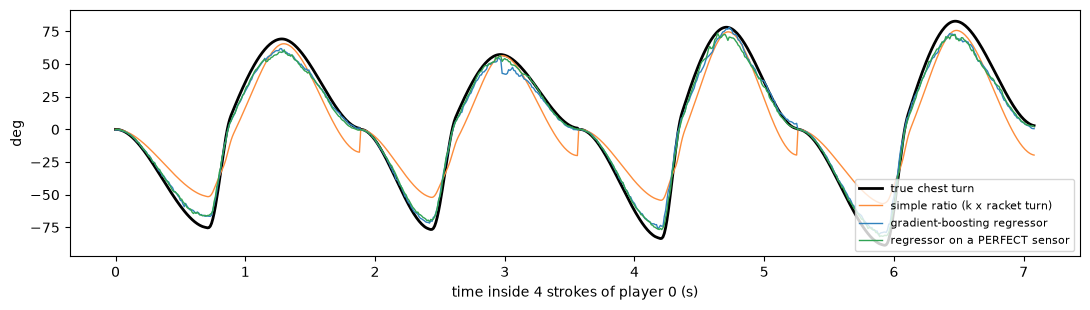

In [10]:
Rs = summ['rotation']
names = [('proxy', 'simple ratio (k x racket turn)'), ('hgb', 'gradient-boosting regressor'),
         ('oracle', 'regressor on a PERFECT sensor'), ('proxy_cal5', 'ratio + 5 calibration swings'),
         ('hgb_cal5', 'regressor + 5 calibration swings')]
rows = [f"| {n} | {Rs[m]['rmse']:.1f} | {S['rotation'][m]['rmse']:.1f} | {Rs[m]['peak_coil_mae']:.1f} | {Rs[m]['r']:.3f} |"
        for m, n in names]
display(Markdown('| method | error RMSE (deg) here | in summary.json | peak-coil error (deg) | correlation r |\n'
                 '|---|---|---|---|---|\n' + '\n'.join(rows)))
print('k fitted in each round:', np.round(Rs['k_share'], 2))

sel = np.isin(ROT_TRACE['sid'], np.unique(ROT_TRACE['sid'])[:4])
fig, ax = plt.subplots(figsize=(11, 3.2))
x = np.arange(sel.sum()) / 100
ax.plot(x, ROT_TRACE['true'][sel], 'k', lw=2, label='true chest turn')
for m, c in [('proxy', '#fd8d3c'), ('hgb', '#3182bd'), ('oracle', '#31a354')]:
    ax.plot(x, ROT_TRACE[m][sel], c=c, lw=1, label=dict(names)[m])
ax.set_xlabel('time inside 4 strokes of player 0 (s)'); ax.set_ylabel('deg'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

What the numbers say (expected values from the full run: about 13.8° / 7.1° / 6.6° / 5.3°):

* The **simple ratio** is off by about 14°: players split the turn between chest and arm differently, and one k cannot fit all.
* The **regressor** halves that, to about 7°.
* The **perfect sensor** is barely better (about 6.6°). So a better sensor would not fix it.
* **Five calibration swings** per player (for example from a short video) bring it to about 5°: they teach the model that player's personal split.

## 8. Why the chest turn cannot be fully known

The racket's heading is a **sum**:

> racket turn = chest turn + shoulder turn + wrist turn

The sensor sees only the total. If two numbers add to 10, you cannot tell 7 + 3 from 4 + 6.
The labels file lets us check that the sum is exact, and see how different players split the same racket turn.

max |racket heading - (chest + shoulder + wrist)| over all 564,924 rows: 0.0001 deg


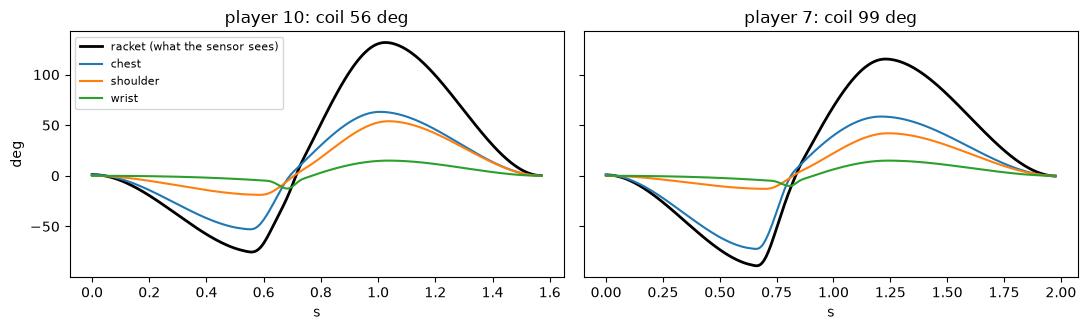

player,0,1,2,3,4,5,6,7,8,9,10,11
true chest share,0.84,0.72,0.60,0.83,0.74,0.85,0.74,0.82,0.80,0.66,0.69,0.76
k fitted on others,0.49,0.50,0.51,0.49,0.50,0.50,0.50,0.49,0.51,0.49,0.50,0.50


In [11]:
s = labels.trunk_angle_deg + labels.shoulder_angle_deg + labels.wrist_angle_deg
print(f'max |racket heading - (chest + shoulder + wrist)| over all {len(labels):,} rows: '
      f'{np.abs(labels.racket_heading_deg - s).max():.4f} deg')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for a, pid in zip(ax, players.sort_values('coil').player.iloc[[0, -1]]):
    g = labels[(labels.player == pid) & (labels.session == 0) & (labels.stroke_id == 3)]
    tt = g.t - g.t.iloc[0]
    a.plot(tt, g.racket_heading_deg, 'k', lw=2, label='racket (what the sensor sees)')
    a.plot(tt, g.trunk_angle_deg, label='chest'); a.plot(tt, g.shoulder_angle_deg, label='shoulder')
    a.plot(tt, g.wrist_angle_deg, label='wrist')
    a.set_title(f'player {pid}: coil {players.coil[pid]:.0f} deg'); a.set_xlabel('s')
ax[0].set_ylabel('deg'); ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
display(pd.DataFrame({'true chest share': Rs['true_share'], 'k fitted on others': Rs['k_share']},
                     index=players.player).T.round(2))

The orientation and the spin are **identical** for any split with the same total. Only a small lever-arm effect on acceleration differs,
and that effect is about as large as the effect of a slightly longer arm, which the model does not know either.
So the remaining 5-7° is a **limit of the sensor placement**, not of the model.
To measure chest rotation properly, put a sensor **on the chest** (and one on the wrist to split arm from wrist).

## 9. Limits and next steps

**Limits**

* All data is **simulated**. The player styles, sensor noise and phase definitions are plausible, but not fitted to real recordings.
  Treat every score as an upper bound.
* Only flat-ish rally forehands from right-handers. No slices, running shots, or open vs closed stance.
* 12 players is small; the per-player spread is wide relative to the mean differences between models.

**Next steps**

1. Record real players with the racket sensor plus motion capture or 2-3 synchronised high-speed cameras, and measure the sim-to-real gap.
2. Add a chest sensor (and a smartwatch) to make chest rotation directly measurable.
3. Try a sequence model (BiGRU / TCN) once real labelled data exist; keep the HMM rules as a safety net.
4. Tune settings (window sizes, HMM minimum durations) inside the training players only (nested validation).

In [12]:
print(f'notebook run time: {time.time() - T_START:.0f} s')

notebook run time: 517 s
